# 00b – Keras Spike: Keras 3 with PyTorch backend on Apple Silicon

## 1. Goal
Short experiment (timebox 1 h) before notebook 05: does **Keras 3 with the PyTorch backend** run reliably on our Macs (MPS)?
At the end we decide: Keras or plain PyTorch for notebooks 05–08.

Steps:
1. Install Keras and set the backend
2. Check which device is used
3. Load EfficientNetB0 and look at it
4. Pass 64 of our own crops through the network
5. Short training with a frozen base network
6. Measure time: MPS vs. CPU
7. Test gradients for Grad-CAM
8. Write down the decision

## 2. Analysis
### Step 1 – Install Keras and set the backend
Keras itself does not compute anything, it needs a **backend**. The backend is chosen with the environment variable `KERAS_BACKEND`,
and it is read **once, at the first `import keras`**. So the variable must be set before Keras is imported.

In [1]:
%pip install keras

  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 10.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 18.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 737.4/737.4 kB 15.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 408.2/408.2 kB 9.2 MB/s eta 0:00:00a 0:00:01
Using cached rich-15.0.0-py3-none-any.whl (310 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.0/97.0 kB 12.8 MB/s eta 0:00:00
Using cached mdurl-0.1.2-py3-none-any.whl (10.0 kB)

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # must come BEFORE the first import of keras

import keras
import torch

print("Keras version:  ", keras.__version__)
print("Keras backend:  ", keras.backend.backend())
print("PyTorch version:", torch.__version__)

Keras version:   3.15.1
Keras backend:   torch
PyTorch version: 2.15.0


**Observation:**

important: set the backend first, before importing keras, we have to define its backend torch. otherwise it wants to go to its standard tensorflow, which ist not installed in the venv at the moment. 

### Step 2 – Check which device is used
With the PyTorch backend, every Keras tensor is in fact a PyTorch tensor, and every PyTorch tensor lives on a **device**:
`cpu`, `cuda` (NVIDIA GPU) or `mps` (Apple GPU). Keras picks a default device on its own.
With `keras.device(...)` we can force a device for a block of code. We will need this in step 6 to compare MPS and CPU.

In [3]:
print("MPS available:", torch.backends.mps.is_available())

# 1) a tensor created by Keras
x = keras.ops.ones((2, 3))
print("Type of x:    ", type(x))
print("x is on:      ", x.device)

# 2) the weights of a Keras layer
layer = keras.layers.Dense(4)
layer.build((None, 3))      # creates the weights for an input with 3 features
print("Weights on:   ", layer.kernel.value.device)

# 3) force the CPU for one block
with keras.device("cpu"):
    y = keras.ops.ones((2, 3))
print("y is on:      ", y.device)

MPS available: True
Type of x:     <class 'torch.Tensor'>
x is on:       mps:0
Weights on:    mps:0
y is on:       cpu


**Observation:** 
Keras uses MPS by default; tensors and weights are on the GPU. With keras.device("cpu") we can force the CPU.

### Step 3 – Load EfficientNetB0 and look at it
We use a network that was already trained on ImageNet (1.2 million photos, 1000 classes). It already "knows" edges, textures and shapes.
- `include_top=False` removes the original head that decides between the 1000 ImageNet classes. We will add our own head for PV / no PV.
- `pooling="avg"` averages the last feature map, so the network returns **one feature vector per image**.
- Keras expects images as `(height, width, channels)` ("channels last"), even with the PyTorch backend. PyTorch itself uses `(channels, height, width)`.

In [4]:
base = keras.applications.EfficientNetB0(
    weights="imagenet",          # pretrained weights (downloaded once, about 16 MB)
    include_top=False,           # without the original 1000-class head
    input_shape=(224, 224, 3),   # height, width, colour channels
    pooling="avg",               # one feature vector per image
)

print("Number of layers:", len(base.layers))
print("Parameters:      ", f"{base.count_params():,}")
print("Input shape:     ", base.input_shape)
print("Output shape:    ", base.output_shape)
print("First layers:    ", [layer.name for layer in base.layers[:4]])
print("Last layers:     ", [layer.name for layer in base.layers[-4:]])

# the network is built from blocks; their names start with "block1a", "block1b", ... "block7a"
blocks = sorted({layer.name.split("_")[0] for layer in base.layers if layer.name.startswith("block")})
print("Blocks:          ", blocks)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Number of layers: 239
Parameters:       4,049,571
Input shape:      (None, 224, 224, 3)
Output shape:     (None, 1280)
First layers:     ['input_layer', 'rescaling', 'normalization', 'rescaling_1']
Last layers:      ['top_conv', 'top_bn', 'top_activation', 'avg_pool']
Blocks:           ['block1a', 'block2a', 'block2b', 'block3a', 'block3b', 'block4a', 'block4b', 'block4c', 'block5a', 'block5b', 'block5c', 'block6a', 'block6b', 'block6c', 'block6d', 'block7a']


**Observation:** 

EfficientNetB0 without top: 4.05 M parameters, one 1280-dim vector per image. Preprocessing (rescaling + normalization) is built in, so we feed raw 0–255 pixels.

### Step 4 – Pass 64 of our own crops through the network
We load 64 images from `train.csv` and send them through `base` as **one batch**.
- Our crops are PNGs with 4 channels (RGBA, saved with `plt.imsave`). `color_mode="rgb"` drops the alpha channel.
- `target_size=(224, 224)` resizes every crop to 224 × 224. The crops have different sizes and aspect ratios, so they get stretched.
- The pixel values stay between 0 and 255: the normalisation is built into EfficientNetB0 (see step 3).

**Your part:** fill in the two `TODO` lines.

In [8]:
import numpy as np
import pandas as pd

train = pd.read_csv("../data/labels/train.csv")
print(len(train), "training images,", round(train["label"].mean() * 100, 1), "% PV")


def load_image(path, size=224):
    img = keras.utils.load_img(path, color_mode="rgb", target_size=(size, size))  # PNG -> RGB, 224 x 224
    return keras.utils.img_to_array(img)                                          # array (224, 224, 3), values 0..255


# TODO 1: take 64 random rows from `train`, reproducibly (hint: DataFrame.sample with random_state)
sample = train.sample(64, random_state=42)

batch = np.stack([load_image(path) for path in sample["path"]])
print("Batch shape:", batch.shape, "| min:", batch.min(), "| max:", batch.max())

# TODO 2: send the batch through `base` and store the result in `features`
#         (hint: there are two ways, `base(...)` and `base.predict(...)` - try one, then the other, and compare type(features))

features = base(batch)

features_predict = base.predict(batch)



print("Features type: ", type(features))
print("Features shape:", features.shape)

print("Features type: ", type(features_predict))
print("Features shape:", features_predict.shape)

1565 training images, 14.1 % PV
Batch shape: (64, 224, 224, 3) | min: 0.0 | max: 255.0
2/2 ━━━━━━━━━━━━━━━━━━━━ 15s 434ms/step
Features type:  <class 'torch.Tensor'>
Features shape: torch.Size([64, 1280])
Features type:  <class 'numpy.ndarray'>
Features shape: (64, 1280)


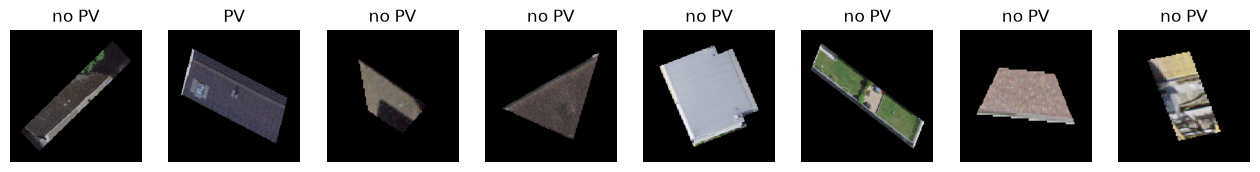

In [9]:
import matplotlib.pyplot as plt

# visual check: the first 8 images of the batch as the network sees them (after resizing)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for ax, img, label in zip(axes, batch, sample["label"]):
    ax.imshow(img.astype("uint8"))
    ax.set_title("PV" if label == 1 else "no PV")
    ax.axis("off")
plt.show()

**Observation:**
oth calls compute the same features; base() returns a torch tensor on MPS, predict() a numpy array in batches of 32. Pixels 0–255. Only 14.1 % PV in train → class weights needed. Stretching to 224 × 224 looks acceptable (open point: padding instead) if the model has problems with very small roofs, maybe we have to adjust the zooming. 
